In [1]:
!pip install pymoo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 27.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 879.5/879.5 kB 28.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [pymoo]


=== EXERCÍCIO 7: RESULTADOS DA OTIMIZAÇÃO (TRADE-OFF) ===

1. Solução de MENOR CUSTO:
   Robôs (x1): 5.00 | Velocidade (x2): 1.00 m/s
   Custo Total (f1): R$ 133.02 mil | Tempo de Ciclo (f2): 63.95 min

2. Solução de MENOR TEMPO:
   Robôs (x1): 16.82 | Velocidade (x2): 3.71 m/s
   Custo Total (f1): R$ 530.30 mil | Tempo de Ciclo (f2): 17.93 min

3. Solução INTERMEDIÁRIA (Equilibrada):
   Robôs (x1): 6.88 | Velocidade (x2): 2.81 m/s
   Custo Total (f1): R$ 235.15 mil | Tempo de Ciclo (f2): 31.68 min



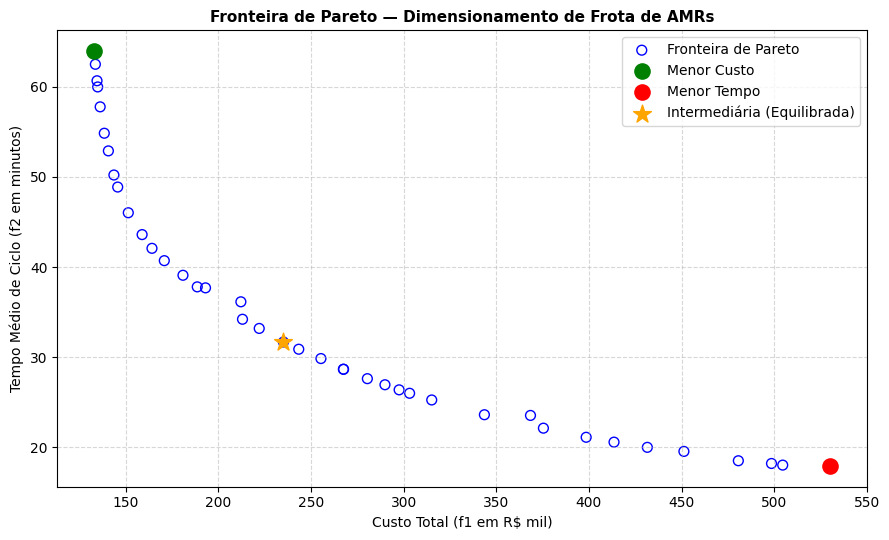

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

class FrotaRobosProblem(ElementwiseProblem):
    def __init__(self):
        # x1 (Número de Robôs): [5, 50], x2 (Velocidade Média): [1.0, 4.0]
        super().__init__(
            n_var=2,
            n_obj=2,
            n_ieq_constr=1,
            xl=np.array([5.0, 1.0]),
            xu=np.array([50.0, 4.0])
        )

    def _evaluate(self, x, out, *args, **kwargs):
        x1, x2 = x[0], x[1]

        # Objetivo 1 — Custo Total de Aquisição e Manutenção (R$ mil)
        f1 = (x1 * 25.0) + (x2**2 * 8.0)

        # Objetivo 2 — Tempo Médio de Ciclo por Entrega (minutos)
        f2 = (120.0 / x1) + (40.0 / x2)

        # Restrição de Bateria/Segurança (g1): Consumo <= 120.0
        g1 = (x1 * (x2**1.5)) - 120.0

        out["F"] = [f1, f2]
        out["G"] = [g1]

# Executando a Otimização com o NSGA-II
problem = FrotaRobosProblem()
algorithm = NSGA2(pop_size=40)

res = minimize(
    problem,
    algorithm,
    termination=("n_gen", 60),
    seed=42,
    verbose=False
)

# Filtrando e exibindo as 3 soluções de interesse no console
if res.X is not None and len(res.X) > 0:
    X_opt = res.X
    F_opt = res.F

    # Encontrando os índices de interesse direto na fronteira
    idx_menor_custo = np.argmin(F_opt[:, 0])
    idx_menor_tempo = np.argmin(F_opt[:, 1])

    # Distância Euclidiana normalizada para encontrar a solução intermediária (equilibrada)
    f1_min, f1_max = F_opt[:, 0].min(), F_opt[:, 0].max()
    f2_min, f2_max = F_opt[:, 1].min(), F_opt[:, 1].max()

    f1_norm = (F_opt[:, 0] - f1_min) / (f1_max - f1_min) if f1_max > f1_min else np.zeros(len(F_opt))
    f2_norm = (F_opt[:, 1] - f2_min) / (f2_max - f2_min) if f2_max > f2_min else np.zeros(len(F_opt))
    dist_ideal = np.sqrt(f1_norm**2 + f2_norm**2)
    idx_intermediaria = np.argmin(dist_ideal)

    print("=== EXERCÍCIO 7: RESULTADOS DA OTIMIZAÇÃO (TRADE-OFF) ===\n")

    print("1. Solução de MENOR CUSTO:")
    print(f"   Robôs (x1): {X_opt[idx_menor_custo][0]:.2f} | Velocidade (x2): {X_opt[idx_menor_custo][1]:.2f} m/s")
    print(f"   Custo Total (f1): R$ {F_opt[idx_menor_custo][0]:.2f} mil | Tempo de Ciclo (f2): {F_opt[idx_menor_custo][1]:.2f} min\n")

    print("2. Solução de MENOR TEMPO:")
    print(f"   Robôs (x1): {X_opt[idx_menor_tempo][0]:.2f} | Velocidade (x2): {X_opt[idx_menor_tempo][1]:.2f} m/s")
    print(f"   Custo Total (f1): R$ {F_opt[idx_menor_tempo][0]:.2f} mil | Tempo de Ciclo (f2): {F_opt[idx_menor_tempo][1]:.2f} min\n")

    print("3. Solução INTERMEDIÁRIA (Equilibrada):")
    print(f"   Robôs (x1): {X_opt[idx_intermediaria][0]:.2f} | Velocidade (x2): {X_opt[idx_intermediaria][1]:.2f} m/s")
    print(f"   Custo Total (f1): R$ {F_opt[idx_intermediaria][0]:.2f} mil | Tempo de Ciclo (f2): {F_opt[idx_intermediaria][1]:.2f} min\n")

    # Gerando o gráfico com a Fronteira de Pareto
    plt.figure(figsize=(9, 5.5))
    plt.scatter(F_opt[:, 0], F_opt[:, 1], color="blue", facecolors="none", edgecolors="blue", s=50, label="Fronteira de Pareto")

    # Marcando os 3 pontos específicos de interesse
    plt.scatter(F_opt[idx_menor_custo, 0], F_opt[idx_menor_custo, 1], color="green", s=120, zorder=5, label="Menor Custo")
    plt.scatter(F_opt[idx_menor_tempo, 0], F_opt[idx_menor_tempo, 1], color="red", s=120, zorder=5, label="Menor Tempo")
    plt.scatter(F_opt[idx_intermediaria, 0], F_opt[idx_intermediaria, 1], color="orange", marker="*", s=180, zorder=5, label="Intermediária (Equilibrada)")

    plt.title("Fronteira de Pareto — Dimensionamento de Frota de AMRs", fontsize=11, fontweight="bold")
    plt.xlabel("Custo Total (f1 em R$ mil)")
    plt.ylabel("Tempo Médio de Ciclo (f2 em minutos)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.savefig("pareto_fronteira_robos.png", dpi=150)
    plt.show()
else:
    print("Nenhuma solução viável encontrada para traçar os resultados.")